# t검정 실습 #

### 1-1 데이터 불러오기 ###

In [2]:
import pandas as pd
mpg = pd.read_csv('mpg.csv')

### 1-2 기술통계분석 ###

In [3]:
mpg.query('category in ["compact", "suv"]') \
    .groupby('category', as_index=False) \
    .agg(n = ('category', 'count'),
         mean = ('cty', 'mean'))

,category,n,mean
0,compact,47,20.12766
1,suv,62,13.50000


→ 카테고리에 따른 빈도(compact: 47, suv: 62)와 cty 평균(compact: 20.12766, suv: 13.5) 구하기 

### 1-3. 필요한 행 추출하여 변수에 할당 ###

In [4]:
compact = mpg.query('category == "compact"')['cty']
suv = mpg.query('category == "suv"')['cty']

In [ ]:
compact.head()

0    18
1    21
2    20
3    21
4    16
Name: cty, dtype: int64

In [17]:
suv.head()

18    14
19    11
20    14
21    13
22    12
Name: cty, dtype: int64

### 1-4. 등분산 가정 t검정 수행 ###

In [9]:
pip install scipy

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/38.6 MB ? eta -:--:--
   -- ------------------------------------- 2.9/38.6 MB 14.0 MB/s eta 0:00:03
   ---------- ----------------------------- 9.7/38.6 MB 24.1 MB/s eta 0:00:02
   ------------- -------------------------- 13.4/38.6 MB 21.5 MB/s eta 0:00:02
   ------------------- -------------------- 18.4/38.6 MB 24.6 MB/s eta 0:00:01
   ------------------- -------------------- 18.4/38.6 MB 24.6 MB/s eta 0:00:01
   ------------------- -------------------- 18.4/38.6 MB 24.6 MB/s eta 0:00:01
   ------------------- -------------------- 18.4/38.6 MB 24.6 MB/s eta 0:00:01
   ------------------- -------------------- 18.4/38.6 MB 24.6 MB/s eta 0:00:01
   ------------------- -------------------- 18.4/38.6 MB 24.6 MB/s eta 0:00:01
   ------------------- -------------------- 18.4/38.6 MB 24.6 MB/s eta 0:00:01
   ------------------- -------------------- 18.4/38.6 MB 24.6 MB


[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: C:\Users\SAMSUNG\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [10]:
from scipy import stats

stats.ttest_ind(compact, suv, equal_var = True)

TtestResult(statistic=np.float64(11.917282584324107), pvalue=np.float64(2.3909550904711282e-21), df=np.float64(107.0))

→ t검정 결과, 유의확률 p값이 0.05 미만이므로 두 카테고리별 cty 평균의 차이가 통계적으로 유의하다고 판단한다. 즉, compact의 cty 평균이 suv의 cty 평균보다 유의미하게 크다.

# T검정 실습2 #

### 2-1 기술통계분석 ###

In [11]:
mpg.query('fl in ["r", "p"]') \
    .groupby('fl', as_index=False) \
    .agg(n = ('fl', 'count'),
         mean = ('cty', 'mean'))

,fl,n,mean
0,p,52,17.365385
1,r,168,16.738095


→ fl에 따른 빈도(p: 52, r: 168)와 cty평균(p: 17.365, r: 16.738)을 구하는 기술통계분석 수행

### 2-2 필요한 행 추출하여 변수에 할당 ###

In [12]:
regular = mpg.query('fl == "r"')['cty']
premium = mpg.query('fl == "p"')['cty']

### 2-3 등분산 가정 t검정 실시 ###

In [13]:
stats.ttest_ind(regular, premium, equal_var=True)

TtestResult(statistic=np.float64(-1.066182514588919), pvalue=np.float64(0.28752051088667036), df=np.float64(218.0))

→ t검정 결과, 유의확률 p값이 0.05보다 크므로 tl별 cty평균의 차이가 유의미하다고 볼 수 없다. 즉, tl이 r인 집단과 tl이 p인 집단의 cty 평균에는 통계적으로 유의미한 차이가 없다.

# 상관분석 실습 #

### 3-1 데이터 불러오기 ###

In [14]:
economics = pd.read_csv('economics.csv')

In [15]:
economics.head()

,date,pce,pop,psavert,uempmed,unemploy
0,1967-07-01,506.7,198712.0,12.6,4.5,2944
1,1967-08-01,509.8,198911.0,12.6,4.7,2945
2,1967-09-01,515.6,199113.0,11.9,4.6,2958
3,1967-10-01,512.2,199311.0,12.9,4.9,3143
4,1967-11-01,517.4,199498.0,12.8,4.7,3066


### 3-2 상관행렬 구하기 ###

In [19]:
economics[['unemploy', 'pce']].corr()

,unemploy,pce
unemploy,1.000000,0.614518
pce,0.614518,1.000000


→ 상관행렬 확인 결과, 두 변수의 상관계수가 0.61로 양수이므로 정비례 관계임

### 3-3 유의확률 구하기 ###

In [20]:
stats.pearsonr(economics['unemploy'], economics['pce'])

PearsonRResult(statistic=np.float64(0.614517614193208), pvalue=np.float64(6.773527303290177e-61))

→ 피어슨분석 결과 유의확률 p값이 0.05 미만이므로 상관계수 0.61이 통계적으로 유의미한 수치임을 검증하였음

### 3-4 상관행렬 히트맵 만들기 ###

In [21]:
mtcars = pd.read_csv('mtcars.csv')

In [22]:
mtcars.head()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


In [23]:
car_cor = mtcars.corr()
car_cor = round(car_cor, 2)
car_cor

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
mpg,1.00,-0.85,-0.85,-0.78,0.68,-0.87,0.42,0.66,0.60,0.48,-0.55
cyl,-0.85,1.00,0.90,0.83,-0.70,0.78,-0.59,-0.81,-0.52,-0.49,0.53
disp,-0.85,0.90,1.00,0.79,-0.71,0.89,-0.43,-0.71,-0.59,-0.56,0.39
hp,-0.78,0.83,0.79,1.00,-0.45,0.66,-0.71,-0.72,-0.24,-0.13,0.75
drat,0.68,-0.70,-0.71,-0.45,1.00,-0.71,0.09,0.44,0.71,0.70,-0.09
wt,-0.87,0.78,0.89,0.66,-0.71,1.00,-0.17,-0.55,-0.69,-0.58,0.43
qsec,0.42,-0.59,-0.43,-0.71,0.09,-0.17,1.00,0.74,-0.23,-0.21,-0.66
vs,0.66,-0.81,-0.71,-0.72,0.44,-0.55,0.74,1.00,0.17,0.21,-0.57
am,0.60,-0.52,-0.59,-0.24,0.71,-0.69,-0.23,0.17,1.00,0.79,0.06
gear,0.48,-0.49,-0.56,-0.13,0.70,-0.58,-0.21,0.21,0.79,1.00,0.27


→ 모든 변수의 상관관계를 나타낸 상관행렬 출력. 상관계수가 음수면 두 변수가 반비례관계, 상관계수가 양수면 두 변수가 정비례관계임을 유추할 수 있음

In [25]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi' : '120',
                     'figure.figsize' : [7.5, 5.5]})

<Axes: >

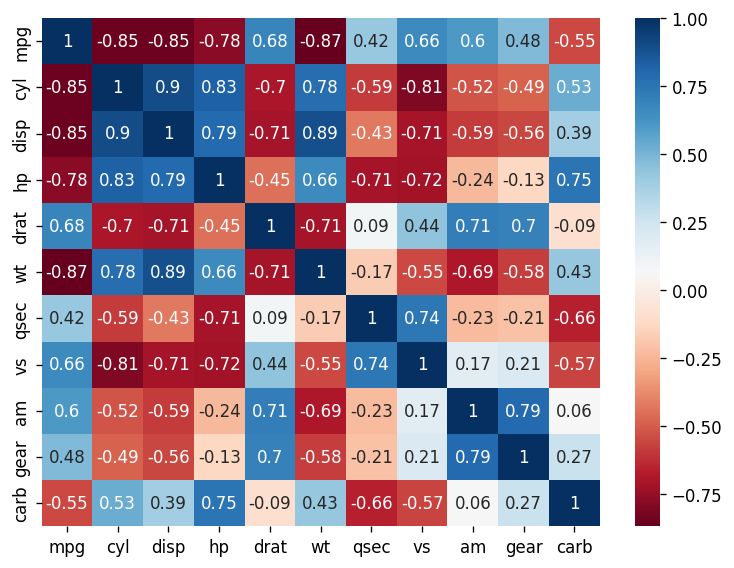

In [26]:
import seaborn as sns
sns.heatmap(car_cor,
            annot=True,
            cmap='RdBu')

→ 상관행렬을 더 이해하기 쉽게 시각화한 히트맵. 양수면 Blue, 음수면 Red로 표현되며 투명도를 통해 상관관계의 정도를 파악할 수 있음

### 3-5 대각행렬 제거한 상관행렬 히트맵 만들기 ###

In [27]:
import numpy as np
mask = np.zeros_like(car_cor)
mask

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

→ 0으로 채워진 행렬 만들기

In [28]:
mask[np.triu_indices_from(mask)] = 1
mask

array([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1.],
       [0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1.],
       [0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.],
       [0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]])

→ 오른쪽 위 대각 행렬을 1로 바꿔 채우기

<Axes: >

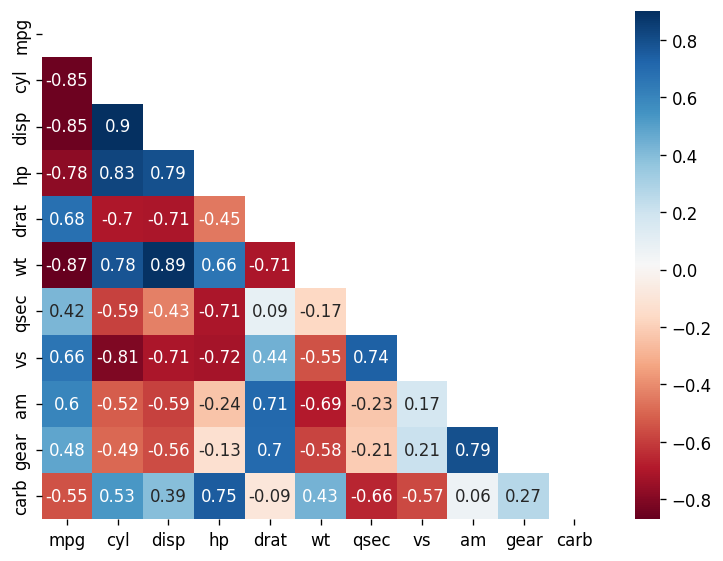

In [29]:
sns.heatmap(data= car_cor,
            annot=True,
            cmap='RdBu',
            mask=mask)

In [30]:
mask_new = mask[1:, :-1]
cor_new = car_cor.iloc[1:, :-1]

→ mask와 상관행렬의 첫번쨰 행과 마지막 열 제거하기

<Axes: >

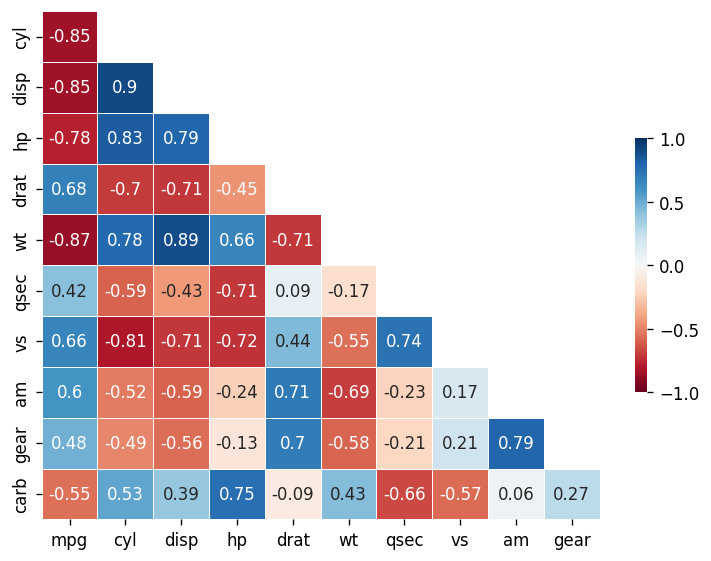

In [32]:
sns.heatmap(data= cor_new,
            annot=True,
            cmap='RdBu',
            mask=mask_new,
            linewidths=.5,
            vmax=1,
            vmin=-1,
            cbar_kws={'shrink' : .5})

→ 중복된 부분이 제거되어 한결 보기 편해진 히트맵 출력 완료!